# 03 — Modelos (Lending Club)

**Proyecto final de Machine Learning — Entrega final**

Este notebook presenta y discute la fase de modelado. El entrenamiento completo
vive en **`src/train.py`** (script principal reproducible); aquí se cargan sus
resultados (`outputs/`) y se analizan. Para reentrenar desde el notebook, poner
`RUN_TRAINING = True` (≈15 min con el dataset completo en un portátil de 8 GB).

**Resumen del protocolo** (ninguna decisión se toma mirando el test):

| Paso | Datos usados |
|---|---|
| Búsqueda de hiperparámetros (`TimeSeriesSplit`, 4 folds) | submuestra aleatoria del 25% del **train**, ordenada por fecha |
| Elección del umbral operativo (máx. F1) | 15% más reciente del **train** (bloque de selección) |
| Elección del modelo final | mayor ROC-AUC medio en la **CV temporal** |
| Evaluación final (una sola vez) | **test out-of-time** (préstamos emitidos 2016-11 a 2018-12) |

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data import RANDOM_SEED, TARGET
from src import evaluate as ev

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.4f}".format)
np.random.seed(RANDOM_SEED)

import os
OUT = Path(os.environ.get("ML_OUT", ROOT / "outputs"))            # resultados de `python -m src.train`
FIG = Path(os.environ.get("ML_FIG", ROOT / "reports" / "figures"))

In [2]:
RUN_TRAINING = False   # True = reentrenar todo con src/train.py (lento)

if RUN_TRAINING:
    from src.train import run
    run(str(ROOT / "data" / "accepted_2007_to_2018Q4.csv.gz"))

metrics = json.load(open(OUT / "metrics.json"))
cv_table = pd.read_csv(OUT / "cv_results.csv")
trials = pd.read_csv(OUT / "cv_all_trials.csv")
preds = pd.read_parquet(OUT / "predictions_test.parquet")
print("Modelo final (elegido por CV):", metrics["final_model"])
print("Tiempo total del pipeline:", metrics["runtime_minutes"], "min")

Modelo final (elegido por CV): hist_gradient_boosting
Tiempo total del pipeline: 14.2 min


## 1. Datos y partición

In [3]:
d = metrics["data"]
pd.DataFrame({
    "n préstamos": [d["n_train"], d["n_test"]],
    "periodo de emisión": [" a ".join(d["train_period"]), " a ".join(d["test_period"])],
    "tasa de default": [d["train_default_rate"], d["test_default_rate"]],
}, index=["train", "test out-of-time"])

,n préstamos,periodo de emisión,tasa de default
train,1089321,2007-06 a 2016-10,0.1993
test out-of-time,280245,2016-11 a 2018-12,0.2631


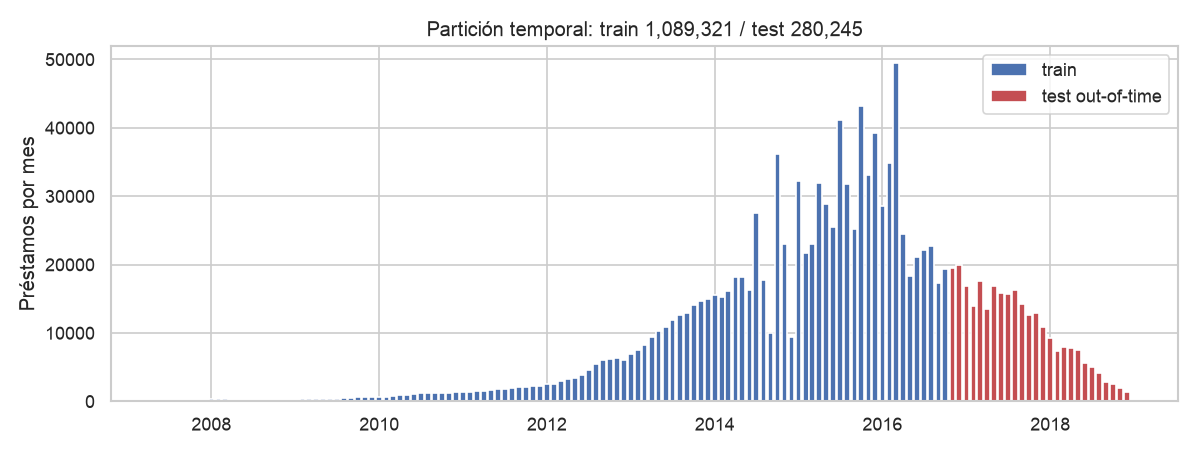

In [4]:
display(Image(FIG / "10_temporal_split.png"))

Se usa el **dataset completo** (no la muestra del 8% de la entrega previa).
La partición es temporal: el modelo se entrena con préstamos antiguos y se evalúa
con préstamos emitidos después, igual que se usaría en producción. Los topes de
winsorización de `annual_inc` y `dti` se calcularon solo con train:

In [5]:
d["winsor_thresholds"]

{'annual_inc_p99': 250000.0, 'dti_cap': 37.90110000000102}

## 2. Modelos comparados y espacios de búsqueda

| Modelo | Familia | Preprocesamiento | Hiperparámetros buscados |
|---|---|---|---|
| `dummy_prior` | referencia trivial | — | — |
| `logreg_baseline` | lineal (baseline de la entrega previa) | imputación + escalado + one-hot | ninguno (C=1, sin balanceo) |
| `logreg_tuned` | lineal regularizada | imputación + escalado + one-hot | `C` ∈ {0.01, 0.1, 1}, `class_weight` ∈ {None, balanced} (grid, 6 combinaciones) |
| `random_forest` | bagging de árboles | imputación + codificación ordinal | `max_depth`, `min_samples_leaf`, `max_features`, `class_weight` (búsqueda aleatoria, 6 combinaciones; 200 árboles, 30% de filas por árbol) |
| `hist_gradient_boosting` | boosting de árboles | imputación + categóricas nativas | `learning_rate`, `max_leaf_nodes`, `min_samples_leaf`, `l2_regularization`, `class_weight` (búsqueda aleatoria, 10 combinaciones; early stopping) |

Todos los preprocesamientos están dentro de un `Pipeline`, así que en cada fold
de la validación cruzada se ajustan solo con los datos de entrenamiento de ese fold.

## 3. Búsqueda de hiperparámetros (validación cruzada temporal)

In [6]:
cv_show = cv_table.copy()
cv_show["best_params"] = cv_show["best_params"].astype(str)
cv_show.sort_values("cv_roc_auc_mean", ascending=False)

,model,cv_roc_auc_mean,cv_roc_auc_std,best_params,search_seconds
4,hist_gradient_boosting,0.7194,0.0141,"{'min_samples_leaf': 1000, 'max_leaf_nodes': 1...",291.8000
2,logreg_tuned,0.7186,0.0134,"{'C': 0.01, 'class_weight': 'balanced'}",40.7000
3,random_forest,0.7184,0.0140,"{'min_samples_leaf': 20, 'max_features': 'sqrt...",218.2000
1,logreg_baseline,0.7182,0.0134,{},5.9000
0,dummy_prior,0.5000,0.0000,{},4.1000


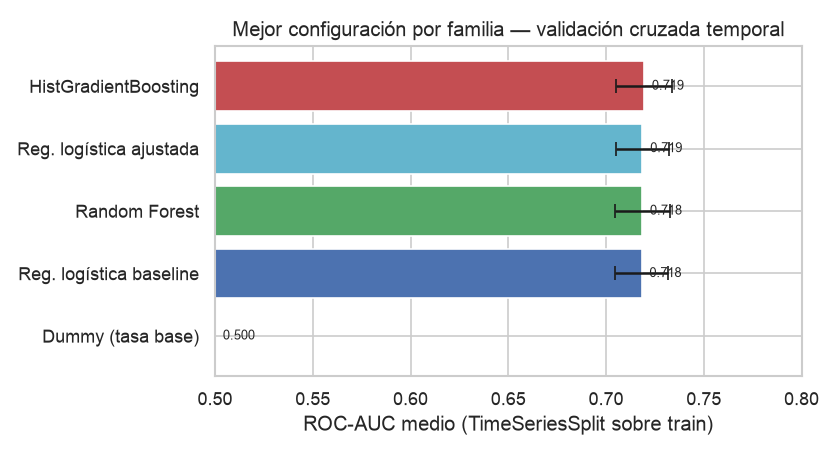

In [7]:
display(Image(FIG / "20_cv_roc_auc.png"))

In [8]:
# Todas las configuraciones probadas, ordenadas dentro de cada familia
(trials.sort_values(["model", "cv_roc_auc_mean"], ascending=[True, False])
       .groupby("model").head(4)
       .style.format({"cv_roc_auc_mean": "{:.4f}", "cv_roc_auc_std": "{:.4f}"}))

,model,params,cv_roc_auc_mean,cv_roc_auc_std
0,dummy_prior,{},0.5000,0.0000
19,hist_gradient_boosting,"{""clf__min_samples_leaf"": 1000, ""clf__max_leaf_nodes"": 15, ""clf__learning_rate"": 0.03, ""clf__l2_regularization"": 1.0, ""clf__class_weight"": null}",0.7194,0.0141
20,hist_gradient_boosting,"{""clf__min_samples_leaf"": 1000, ""clf__max_leaf_nodes"": 15, ""clf__learning_rate"": 0.1, ""clf__l2_regularization"": 0.0, ""clf__class_weight"": ""balanced""}",0.7194,0.0140
17,hist_gradient_boosting,"{""clf__min_samples_leaf"": 300, ""clf__max_leaf_nodes"": 15, ""clf__learning_rate"": 0.03, ""clf__l2_regularization"": 10.0, ""clf__class_weight"": null}",0.7193,0.0140
15,hist_gradient_boosting,"{""clf__min_samples_leaf"": 300, ""clf__max_leaf_nodes"": 15, ""clf__learning_rate"": 0.03, ""clf__l2_regularization"": 1.0, ""clf__class_weight"": ""balanced""}",0.7192,0.0140
1,logreg_baseline,{},0.7182,0.0134
3,logreg_tuned,"{""clf__C"": 0.01, ""clf__class_weight"": ""balanced""}",0.7186,0.0134
2,logreg_tuned,"{""clf__C"": 0.01, ""clf__class_weight"": null}",0.7185,0.0133
5,logreg_tuned,"{""clf__C"": 0.1, ""clf__class_weight"": ""balanced""}",0.7183,0.0135
4,logreg_tuned,"{""clf__C"": 0.1, ""clf__class_weight"": null}",0.7182,0.0134


**Lectura:**
- Las cuatro familias quedan **muy juntas** en la CV temporal: ROC-AUC entre **0.718 y 0.719**, con una desviación entre folds (≈0.014) mayor que la diferencia entre modelos. La variación entre periodos de tiempo pesa más que la elección del algoritmo.
- **HistGradientBoosting** obtiene el mejor promedio (0.7194) y por regla queda como **modelo final**, elegido antes de mirar el test.
- La mejor configuración de boosting es **conservadora**: `learning_rate=0.03`, 15 hojas y `min_samples_leaf=1000`. Con una señal débil, el modelo gana regularizando, no aumentando la complejidad.
- En la regresión logística, `C=0.01` (regularización fuerte) apenas mejora al baseline (0.7186 vs 0.7182). El baseline lineal ya captura casi toda la señal de las variables de originación.
- `class_weight="balanced"` no cambia el AUC, porque solo reescala las probabilidades y no altera el orden de los préstamos. Sí altera la **calibración** (ver sección 5).

## 4. Umbral operativo (bloque de selección del train)

In [9]:
ts = metrics["threshold_selection"]
print("Bloque de selección:", ts["_block"])
pd.DataFrame({
    m: {"umbral": v["threshold"],
        "AUC (selección)": v["selection_metrics"]["roc_auc"],
        "precision": v["selection_metrics"]["at_threshold"]["precision"],
        "recall": v["selection_metrics"]["at_threshold"]["recall"],
        "F1": v["selection_metrics"]["at_threshold"]["f1"]}
    for m, v in ts.items() if not m.startswith("_") and v["selection_metrics"]
}).T

Bloque de selección: {'cutoff': '2016-03-01', 'n_fit': 223387, 'n_selection': 194770, 'selection_base_rate': 0.25490065205113727}


,umbral,AUC (selección),precision,recall,F1
logreg_baseline,0.1672,0.7017,0.3672,0.7123,0.4846
logreg_tuned,0.4616,0.7027,0.3679,0.7100,0.4847
random_forest,0.4061,0.7015,0.3689,0.6959,0.4822
hist_gradient_boosting,0.1667,0.7053,0.3712,0.7018,0.4855


**Lectura:**
- El umbral que maximiza F1 en el bloque de selección (préstamos de 2016-03 a 2016-10, con 25.5% de default) es **≈0.17** para los modelos sin balanceo y **≈0.41–0.46** para los balanceados. Esto confirma que `class_weight` solo desplaza la escala de las probabilidades.
- El umbral 0.5 por defecto no sirve aquí: con el modelo final, el recall a 0.5 en el test es solo **9%**.
- Maximizar F1 es una regla neutral, no una regla de negocio. En la práctica, el umbral debería salir de los costos reales: pérdida por default frente a margen perdido por rechazar a un buen pagador.

## 5. Evaluación final en el test out-of-time

In [10]:
rows = {}
for m, v in metrics["test"].items():
    rows[m] = {"ROC-AUC": v["roc_auc"], "PR-AUC": v["pr_auc"], "KS": v["ks"],
               "Brier": v["brier"], "umbral": v["at_threshold"]["threshold"],
               "precision@umbral": v["at_threshold"]["precision"],
               "recall@umbral": v["at_threshold"]["recall"],
               "F1@umbral": v["at_threshold"]["f1"],
               "% marcados": v["at_threshold"]["flagged_rate"],
               "recall@0.5": v["at_0.5"]["recall"]}
test_table = pd.DataFrame(rows).T
test_table

,ROC-AUC,PR-AUC,KS,Brier,umbral,precision@umbral,recall@umbral,F1@umbral,% marcados,recall@0.5
dummy_prior,0.5000,0.2631,0.0000,0.1979,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000
logreg_baseline,0.6959,0.4305,0.2847,0.1800,0.1672,0.3598,0.7606,0.4885,0.5561,0.0490
logreg_tuned,0.6960,0.4304,0.2851,0.2203,0.4616,0.3668,0.7350,0.4894,0.5271,0.6602
random_forest,0.6960,0.4295,0.2852,0.2070,0.4061,0.3599,0.7605,0.4886,0.5559,0.5658
hist_gradient_boosting,0.7025,0.4380,0.2962,0.1781,0.1667,0.3607,0.7752,0.4923,0.5654,0.0923


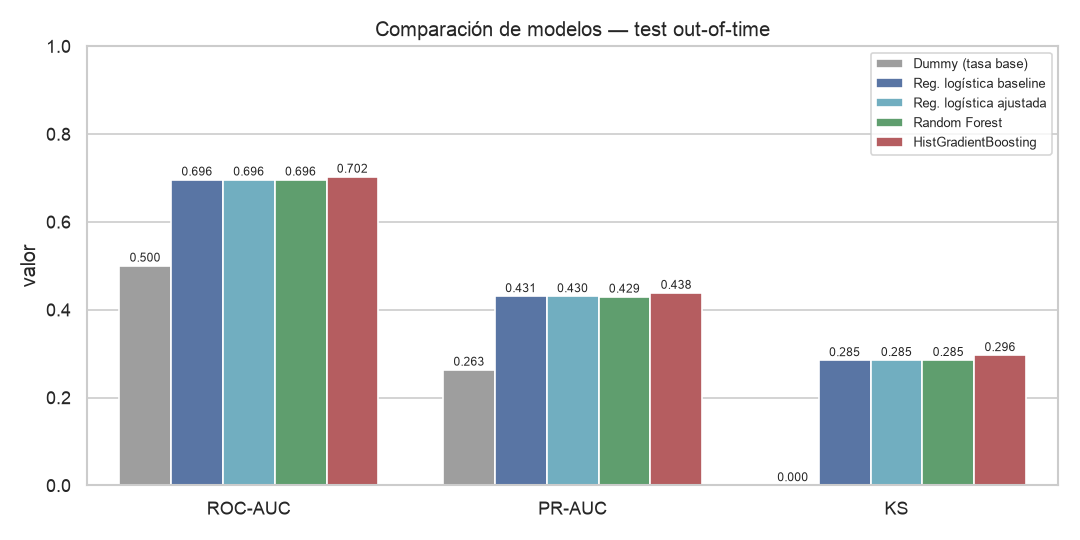

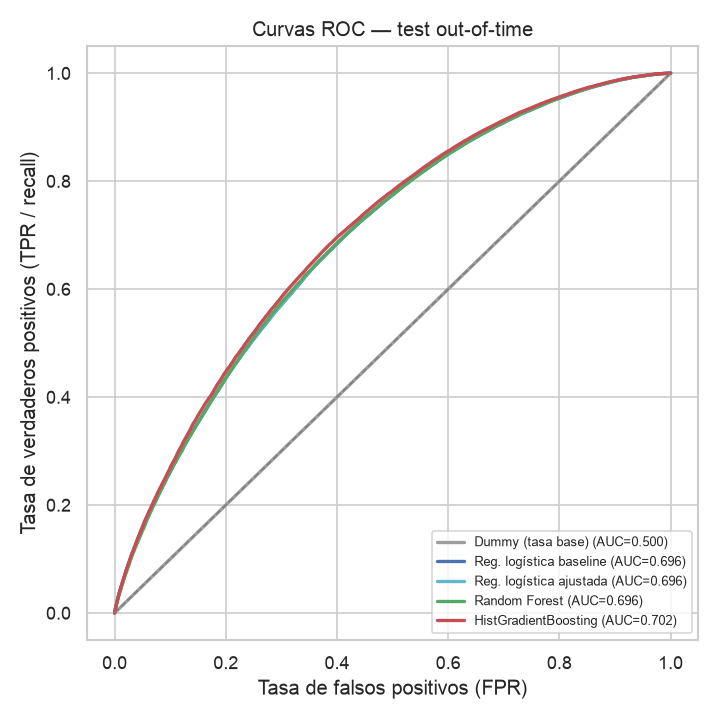

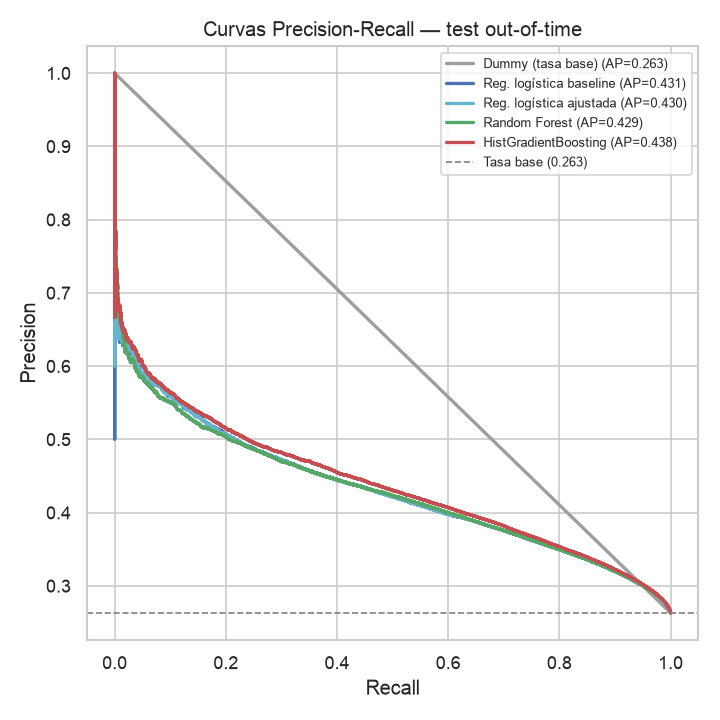

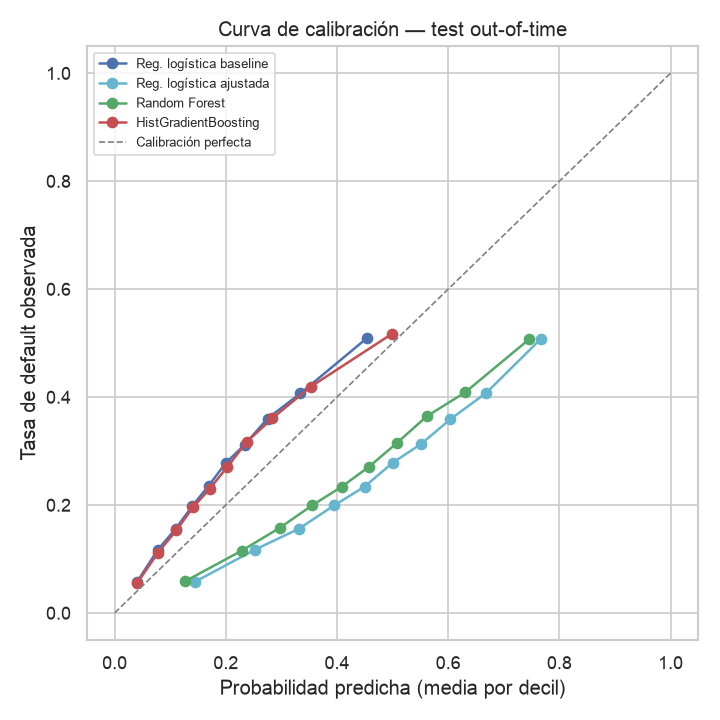

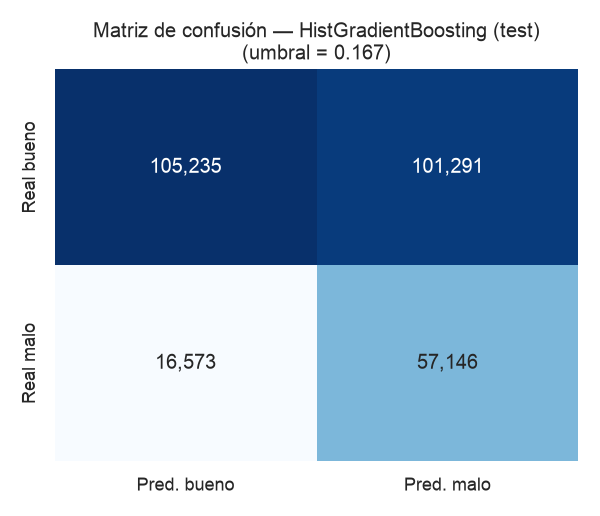

In [11]:
for f in ["23_metric_comparison_test.png", "21_roc_curves_test.png",
          "22_pr_curves_test.png", "24_calibration_test.png",
          "25_confusion_final_test.png"]:
    display(Image(FIG / f))

### 5.1 ¿Las diferencias son reales? Bootstrap pareado en el test

Con ~280 mil préstamos en el test, se remuestrea 300 veces (con reemplazo) y se
calcula la diferencia de ROC-AUC de cada modelo frente al baseline sobre **las
mismas** filas remuestreadas. Un intervalo al 95% que no cruza 0 indica una
diferencia que no se explica por azar de muestreo.

In [12]:
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(RANDOM_SEED)
y = preds[TARGET].to_numpy()
models = [c[2:] for c in preds.columns if c.startswith("p_") and c != "p_dummy_prior"]
P = {m: preds[f"p_{m}"].to_numpy() for m in models}
B = 300
diffs = {m: [] for m in models}
for _ in range(B):
    idx = rng.integers(0, len(y), len(y))
    base = roc_auc_score(y[idx], P["logreg_baseline"][idx])
    for m in models:
        diffs[m].append(roc_auc_score(y[idx], P[m][idx]) - base)

boot = pd.DataFrame({
    m: {"ΔAUC vs baseline": np.mean(v),
        "IC95% inf": np.percentile(v, 2.5),
        "IC95% sup": np.percentile(v, 97.5)}
    for m, v in diffs.items() if m != "logreg_baseline"
}).T
boot.to_csv(OUT / "bootstrap_auc_vs_baseline.csv")
boot

,ΔAUC vs baseline,IC95% inf,IC95% sup
logreg_tuned,0.0001,0.0000,0.0001
random_forest,0.0001,-0.0005,0.0007
hist_gradient_boosting,0.0066,0.0060,0.0072


**Lectura:**
- **HistGradientBoosting** es el mejor en todas las métricas de ranking del test: **ROC-AUC 0.7025**, **PR-AUC 0.438**, **KS 0.296**. El baseline logra 0.6959 / 0.4305 / 0.2847 y el dummy 0.5 / 0.263 / 0.
- La mejora sobre el baseline es **pequeña pero real**: ΔAUC = +0.0066 con un IC95% bootstrap de [+0.0060, +0.0072]. La regresión logística ajustada y el Random Forest **no** mejoran de forma significativa al baseline, porque sus intervalos incluyen 0 o quedan pegados a él.
- El orden de los modelos en el test coincide con el de la CV temporal, así que la selección no fue suerte.
- **Calibración:** el boosting y la logística sin balanceo tienen el mejor Brier (0.178 y 0.180). Aun así, **subestiman** el riesgo del test: la probabilidad media predicha es 0.21 frente a una tasa real de 0.263, efecto de la deriva temporal. Los modelos con `class_weight` balanceado inflan sistemáticamente las probabilidades (media ≈0.43–0.47) y su Brier empeora (0.207–0.220). Por eso no sirven como probabilidad de default sin recalibrar.
- Al umbral operativo, el modelo final detecta **77.5% de los defaults** con una precisión del **36%**, pero marca al **56.5% de los préstamos**. Como regla de aprobación sería demasiado restrictiva; es más útil como score para fijar precios o priorizar revisión.

## 6. Conclusión del modelado

1. Con solo información disponible al originar el préstamo (sin leakage), el techo alcanzable en este problema es un ROC-AUC de **≈0.70** en datos futuros. Los cuatro enfoques convergen ahí, lo que sugiere que el límite está en la información disponible y no en el algoritmo.
2. El modelo final (**HistGradientBoosting**) mejora al baseline de forma estadísticamente significativa pero modesta (+0.007 AUC, +0.008 PR-AUC, +0.012 KS). Su mejor calibración relativa y su costo bajo (≈40 s para entrenar con 1.09 M préstamos) justifican elegirlo.
3. La **regresión logística** queda como alternativa interpretable casi equivalente: pierde menos de 0.01 de AUC y sus coeficientes se explican directamente.
4. Antes de usar el modelo en producción hace falta **recalibrar** con datos recientes, por la subestimación de ≈5 puntos causada por la deriva, y fijar el umbral con una matriz de costos.